# 14 · Gradient Boosting: LightGBM

El gradient boosting (Friedman, 2001) también combina muchos árboles, pero de forma secuencial. Cada árbol nuevo se entrena para corregir los errores que cometen los árboles anteriores. 

Entre las implementaciones disponibles (XGBoost, LightGBM, CatBoost) se ha elegido LightGBM (Ke et al., 2017). Este admite variables categóricas de forma nativa, sin necesidad de codificación one-hot, y es rápido de entrenar.

Se prueban dos funciones de pérdida: L2  y L1.

Puntos del notebook:

1. Cargar datos y variables
2. Preparar las variables para LightGBM
3. Ajuste de hiperparámetros y entrenamiento: ratio (L2)
4. Ajuste de hiperparámetros y entrenamiento: log(ratio) (L2)
5. Ajuste de hiperparámetros y entrenamiento: ratio (L1)
6. Resultados por fold y predicciones de validación
7. Predicciones de test

- **Entrada:** `data/modeling/df_split.parquet` y `data/modeling/folds.csv`
- **Salida:** `data/predictions/lgbm_valid.parquet` y `data/predictions/lgbm_test.parquet`

In [156]:
import sys
from pathlib import Path

# Raíz del repositorio (la carpeta que contiene src/), para poder importar src
RAIZ = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").is_dir())
if str(RAIZ) not in sys.path:
    sys.path.insert(0, str(RAIZ))

from itertools import product

import lightgbm
import matplotlib.pyplot as plt
import pandas as pd
from lightgbm import LGBMRegressor

from src.modelado import (CONFIG_LGBM_FINAL, OBJETIVO, ajustar_y_predecir, buscar_hiperparametros,
                          cargar_datos_modelado, evaluar_en_folds, preparar_para_lightgbm,
                          rellenar_desconocidas, obtener_fold, metricas)
from src.rutas import FIGURES, PREDICTIONS

pd.set_option("display.max_columns", None)
pd.set_option("display.width", None)
print("LightGBM", lightgbm.__version__)

LightGBM 4.7.0


## 1. Cargar datos y variables

In [157]:
df, MESES_VALIDACION = cargar_datos_modelado()
df = rellenar_desconocidas(df)
print(df.shape)

(14146, 15)


## 2. Preparar las variables para LightGBM

LightGBM puede trabajar con categorías sin pasar a números, eso es beneficioso teniendo en cuenta que Random Forest cortaba los grupos de categoria en base a número contiguos. Basta con convertir las variables categóricas al tipo `category` de pandas.

In [158]:
df = preparar_para_lightgbm(df)
df.dtypes

fecha_fase          datetime64[ns]
IDMOTask                    object
smOrdenId                   object
TipoFase                  category
CodigoMaquina             category
Familia Maquinas          category
Línea Producto            category
Família Producto          category
Quantity                   float64
TiempoPrevisto             float64
ratio                      float64
inicio_orden        datetime64[ns]
mes_orden                   object
split                       object
maquina_no_vista              bool
dtype: object

## 3. Ajuste de hiperparámetros y entrenamiento: ratio (L2)

### 3.1 Evaluar la mejor combinación entre `num_leaves` (NL) y `min_child_samples` (MCS)

Se fija `n_estimators` = 500 y `learning_rate` = 0,05.

Para visualizar cada rejilla se usan dos funciones, en ratio y en log(ratio). La primera dibuja dos mapas de calor: el MAE en validación de todas las combinaciones y la diferencia entre el error de validación y el de entrenamiento, que mide el sobreajuste. Leídos juntos, interesa la zona con menor error en validación y menor diferencia. La segunda dibuja la curva de entrenamiento frente a validación según `num_leaves`, para el `min_child_samples` elegido.

In [159]:
def grafico_rejilla_lgbm(ajuste, version):
    """Dos mapas de calor de la rejilla: MAE en validación y diferencia validación − train (sobreajuste)."""
    ajuste = ajuste.assign(diferencia=ajuste["MAE_medio_val"] - ajuste["MAE_train"])
    paneles = [("MAE_medio_val", f"MAE en validación ({version})", "viridis_r"),
               ("diferencia", f"Diferencia validación − train ({version})", "Reds")]

    fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
    for k, (columna, titulo, colores) in enumerate(paneles):
        # filas = num_leaves, columnas = min_child_samples; se redondea para que el color coincida con el número escrito
        tabla = ajuste.pivot(index="num_leaves", columns="min_child_samples", values=columna).round(3)
        im = ax[k].imshow(tabla.values, cmap=colores, aspect="auto")
        ax[k].set_xticks(range(len(tabla.columns)), tabla.columns)
        ax[k].set_yticks(range(len(tabla.index)), tabla.index)
        for i in range(tabla.shape[0]):                  # escribe el valor en cada celda
            for j in range(tabla.shape[1]):
                ax[k].text(j, i, f"{tabla.values[i, j]:.3f}", ha="center", va="center", fontsize=8)
        ax[k].set(xlabel="min_child_samples", ylabel="num_leaves", title=titulo)
        fig.colorbar(im, ax=ax[k])

    plt.tight_layout()
    plt.savefig(FIGURES / f"14_lgbm_rejilla_{version}.png", dpi=200, bbox_inches="tight")
    plt.show()


def grafico_train_val_lgbm(ajuste, version, nl_elegido, mcs_elegido):
    """Curva de MAE en train y en validación según num_leaves, para el min_child_samples elegido."""
    sub = ajuste[ajuste["min_child_samples"] == mcs_elegido].sort_values("num_leaves")
    plt.figure(figsize=(7, 4.5))
    plt.plot(sub["num_leaves"], sub["MAE_train"], marker="o", label="train")
    plt.plot(sub["num_leaves"], sub["MAE_medio_val"], marker="o", label="validación")
    plt.axvline(nl_elegido, color="red", linestyle="--", label="configuración elegida")
    plt.xlabel("num_leaves")
    plt.ylabel("MAE")
    plt.title(f"LightGBM ({version}): train frente a validación (min_child_samples = {mcs_elegido})")
    plt.legend()
    plt.savefig(FIGURES / f"14_lgbm_train_val_{version}.png", dpi=200, bbox_inches="tight")
    plt.show()

In [160]:
NL  = [4, 7, 10, 15, 30, 45, 60]
MCS = [10, 20, 35, 50]

modelo_lgbm = LGBMRegressor(n_estimators=500, learning_rate=0.05, random_state=42, verbose=-1)

rejilla = [{"num_leaves": nl, "min_child_samples": mcs} for nl, mcs in product(NL, MCS)]
ajuste_lgbm = buscar_hiperparametros(modelo_lgbm, rejilla, df, MESES_VALIDACION)
ajuste_lgbm.sort_values("MAE_medio_val").round(3)

,num_leaves,min_child_samples,MAE_train,MAE_medio_val,RMSE_medio,MAE_por_fold
6,7,35,0.822,0.847,1.217,"[0.903, 0.813, 0.823]"
10,10,35,0.812,0.847,1.218,"[0.906, 0.813, 0.822]"
12,15,10,0.790,0.847,1.219,"[0.901, 0.814, 0.826]"
9,10,20,0.809,0.847,1.218,"[0.905, 0.813, 0.824]"
4,7,10,0.818,0.847,1.219,"[0.906, 0.814, 0.822]"
5,7,20,0.820,0.847,1.218,"[0.906, 0.814, 0.822]"
8,10,10,0.806,0.847,1.218,"[0.905, 0.814, 0.824]"
11,10,50,0.814,0.848,1.219,"[0.907, 0.816, 0.82]"
13,15,20,0.795,0.848,1.220,"[0.906, 0.812, 0.825]"
7,7,50,0.823,0.848,1.218,"[0.908, 0.815, 0.822]"


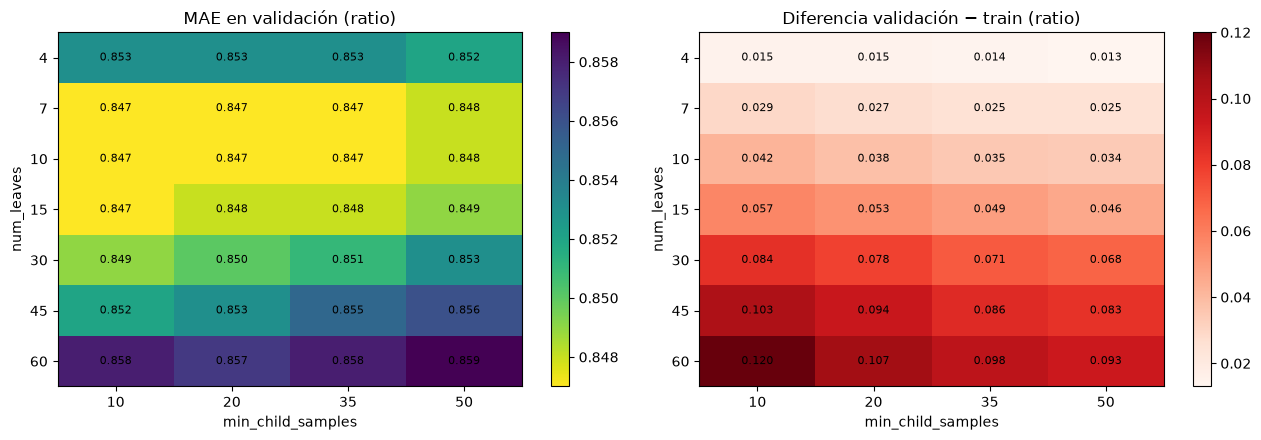

In [161]:
grafico_rejilla_lgbm(ajuste_lgbm, "ratio")

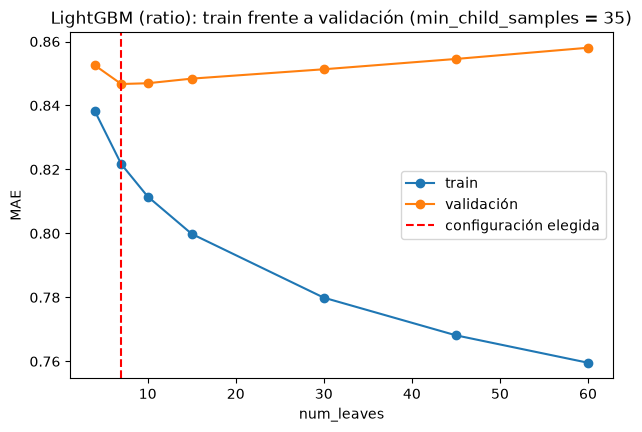

In [162]:
grafico_train_val_lgbm(ajuste_lgbm, "ratio", nl_elegido=7, mcs_elegido=35)

Los dos mapas muestran que `num_leaves` es el hiperparámetro que más influye; `min_child_samples` solo ajusta.

En validación, el MAE forma una meseta entre 7 y 15 hojas. Con 4 hojas el modelo se queda corto y a partir de 30 empeora progresivamente.

La diferencia entre validación y entrenamiento crece con el número de hojas: árboles más grandes se ajustan más al entrenamiento sin mejorar en validación. Subir `min_child_samples` reduce esa diferencia, sobre todo en los árboles grandes, pero a partir de 30 hojas lo hace a costa de empeorar el error en validación.

Se adopta `num_leaves` = 7 y `min_child_samples` = 35: tiene el menor MAE en validación (0,847) y la menor diferencia con el entrenamiento (0,025) entre las combinaciones que lo empatan.

### 3.2 Evaluar `n_estimators` (NE) con `num_leaves` = 7 y `min_child_samples` = 35

In [163]:
modelo_lgbm = LGBMRegressor(num_leaves=7, min_child_samples=35, learning_rate=0.05,
                            random_state=42, verbose=-1)

ajuste_lgbm_ne = buscar_hiperparametros(modelo_lgbm, [{"n_estimators": ne} for ne in [250, 500, 750, 1000]],
                                        df, MESES_VALIDACION)
ajuste_lgbm_ne.round(3)

,n_estimators,MAE_train,MAE_medio_val,RMSE_medio,MAE_por_fold
0,250,0.835,0.852,1.222,"[0.911, 0.819, 0.826]"
1,500,0.822,0.847,1.217,"[0.903, 0.813, 0.823]"
2,750,0.814,0.845,1.216,"[0.901, 0.813, 0.822]"
3,1000,0.808,0.845,1.217,"[0.901, 0.813, 0.822]"


Con `num_leaves` = 7 y `min_child_samples` = 35 fijos, el MAE en validación mejora al pasar de 250 a 500 árboles (0,852 → 0,847) y algo más hasta 750 (0,845), con una mejora consistente en los 3 folds y también en RMSE. A partir de 750 la validación deja de mejorar, mientras que el error en entrenamiento sigue bajando y se aleja del de validación (diferencia de 0,031 con 750 y 0,037 con 1000): más árboles solo memorizan.

Con árboles pequeños (7 hojas), cada árbol corrige menos error y hacen falta más árboles que con 15 hojas, donde 500 eran suficientes. Se adopta **`n_estimators` = 750**.

Configuración final (ratio): `num_leaves` = 7, `min_child_samples` = 35, `n_estimators` = 750, `learning_rate` = 0,05.

## 4. Ajuste de hiperparámetros y entrenamiento: log(ratio) (L2)

In [164]:
NL  = [4, 7, 10, 15, 30, 45, 60]
MCS = [10, 20, 35, 50]

modelo_lgbm_log = LGBMRegressor(n_estimators=500, learning_rate=0.05, random_state=42, verbose=-1)

rejilla = [{"num_leaves": nl, "min_child_samples": mcs} for nl, mcs in product(NL, MCS)]
ajuste_lgbm_log = buscar_hiperparametros(modelo_lgbm_log, rejilla, df, MESES_VALIDACION, log=True)
ajuste_lgbm_log.sort_values("MAE_medio_val").round(3)

,num_leaves,min_child_samples,MAE_train,MAE_medio_val,RMSE_medio,MAE_por_fold
8,10,10,0.771,0.834,1.288,"[0.895, 0.802, 0.804]"
12,15,10,0.757,0.834,1.287,"[0.894, 0.799, 0.808]"
10,10,35,0.775,0.834,1.289,"[0.897, 0.8, 0.806]"
9,10,20,0.774,0.835,1.291,"[0.896, 0.802, 0.807]"
7,7,50,0.786,0.836,1.292,"[0.896, 0.804, 0.807]"
11,10,50,0.778,0.836,1.291,"[0.897, 0.802, 0.808]"
14,15,35,0.765,0.836,1.291,"[0.897, 0.803, 0.808]"
15,15,50,0.768,0.836,1.291,"[0.897, 0.803, 0.808]"
13,15,20,0.761,0.836,1.291,"[0.898, 0.801, 0.81]"
4,7,10,0.783,0.836,1.292,"[0.896, 0.806, 0.807]"


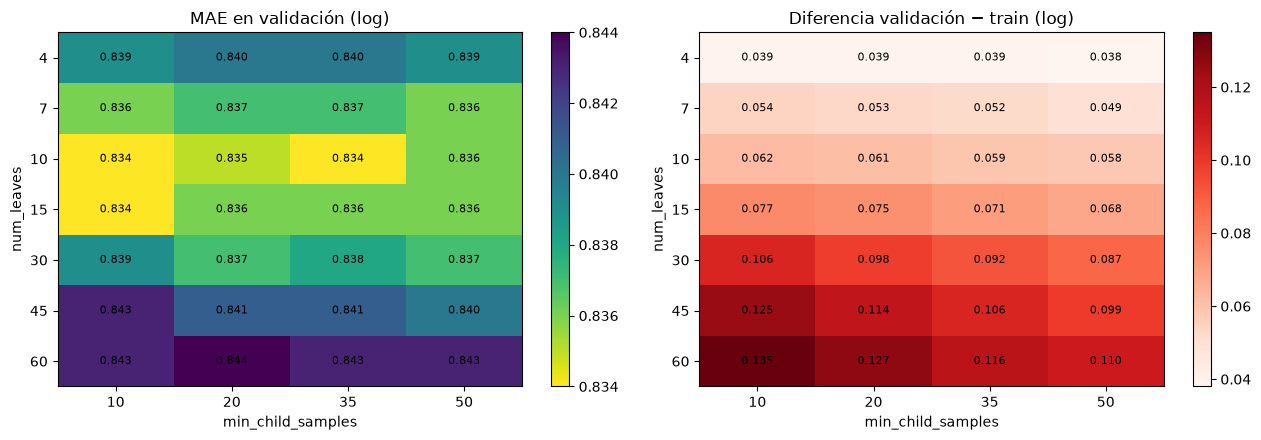

In [165]:
grafico_rejilla_lgbm(ajuste_lgbm_log, "log")

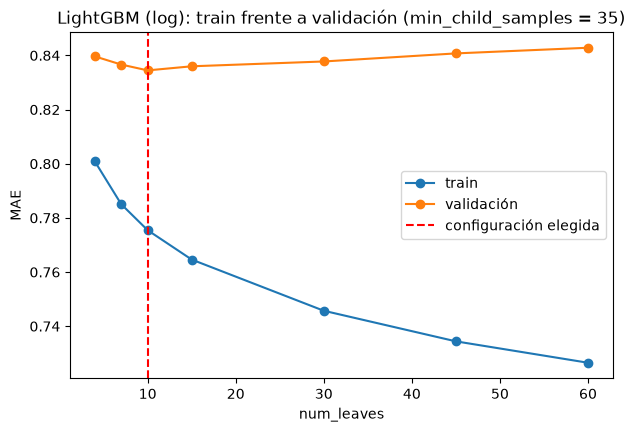

In [166]:
grafico_train_val_lgbm(ajuste_lgbm_log, "log", nl_elegido=10, mcs_elegido=35)

El comportamiento general es el mismo que en la versión ratio: `num_leaves` es el hiperparámetro que más influye, con 4 hojas el modelo se queda corto (0,839–0,840) y a partir de 30 empeora progresivamente (hasta 0,844). Sin embargo, la meseta se desplaza hacia árboles algo mayores: el menor MAE en validación (0,834) se alcanza con 10 hojas.

La diferencia entre validación y entrenamiento es mayor que en la versión ratio para el mismo tamaño de árbol (0,049–0,054 con 7 hojas, frente a 0,025–0,029 en ratio), y crece igualmente con el número de hojas. A diferencia de la versión ratio, ninguna combinación obtiene a la vez el menor error y la menor diferencia.

Se aplica el mismo criterio que en la versión ratio: el menor MAE en validación y, entre las combinaciones que lo empatan, la menor diferencia con el entrenamiento. Se adopta `num_leaves` = 10 y `min_child_samples` = 35 (MAE 0,834, diferencia 0,059).

In [167]:
modelo_lgbm_log = LGBMRegressor(num_leaves=10, min_child_samples=35, learning_rate=0.05,
                                random_state=42, verbose=-1)

ajuste_lgbm_log_ne = buscar_hiperparametros(modelo_lgbm_log,
                                            [{"n_estimators": ne} for ne in [250, 500, 750, 1000]],
                                            df, MESES_VALIDACION, log=True)
ajuste_lgbm_log_ne.round(3)

,n_estimators,MAE_train,MAE_medio_val,RMSE_medio,MAE_por_fold
0,250,0.789,0.837,1.295,"[0.9, 0.804, 0.808]"
1,500,0.775,0.834,1.289,"[0.897, 0.8, 0.806]"
2,750,0.768,0.835,1.290,"[0.896, 0.8, 0.809]"
3,1000,0.762,0.835,1.291,"[0.894, 0.8, 0.811]"


Con `num_leaves` = 10 y `min_child_samples` = 35 fijos, el MAE en validación mejora de 250 a 500 árboles (0,837 → 0,834) y a partir de ahí empeora en un punto (0,835 con 750 y 1000), igual que el RMSE. El error en entrenamiento sigue bajando y la diferencia con validación crece. Los árboles adicionales solo memorizan. Por folds, el resultado es mixto (febrero mejora ligeramente y abril empeora), sin una mejora consistente más allá de 500.

A diferencia de la versión ratio, que con árboles de 7 hojas necesitaba 750, aquí los árboles son algo mayores (10 hojas) y cada uno corrige más error, por lo que el óptimo se alcanza antes. Se adopta **`n_estimators` = 500**.

Configuración final (log(ratio)): `num_leaves` = 10, `min_child_samples` = 35, `n_estimators` = 500, `learning_rate` = 0,05.

## 5. Ajuste de hiperparámetros y entrenamiento: ratio (L1)

Hasta ahora todos los modelos se han entrenado con la función de pérdida por defecto, L2 (error al cuadrado), que lleva la predicción hacia la media. Sin embargo, la métrica más interesante para este proyecto es el MAE, que premia acertar la mediana.

Ahora se prueba la función de pérdida L1, que minimiza el error absoluto: todos los errores pesan igual, sin penalizar más los grandes. Con L1 la predicción apunta a la mediana.

Será interesante compararlo con log(ratio), ya que a efectos prácticos ambas opciones buscan lo mismo: acercar la predicción a la fase típica. L1 lo hace de forma directa y log(ratio), de forma indirecta.

In [168]:
NL  = [4, 7, 10, 15, 30, 45, 60]
MCS = [10, 20, 35, 50]

modelo_lgbm_l1 = LGBMRegressor(objective="l1",       # L1: error absoluto, apunta a la mediana
                               n_estimators=500, learning_rate=0.05, random_state=42, verbose=-1)

rejilla = [{"num_leaves": nl, "min_child_samples": mcs} for nl, mcs in product(NL, MCS)]
ajuste_lgbm_l1 = buscar_hiperparametros(modelo_lgbm_l1, rejilla, df, MESES_VALIDACION)
ajuste_lgbm_l1.sort_values("MAE_medio_val").round(3)

,num_leaves,min_child_samples,MAE_train,MAE_medio_val,RMSE_medio,MAE_por_fold
16,30,10,0.742,0.846,1.317,"[0.915, 0.806, 0.816]"
12,15,10,0.763,0.848,1.318,"[0.91, 0.813, 0.82]"
4,7,10,0.786,0.848,1.319,"[0.913, 0.813, 0.817]"
15,15,50,0.769,0.848,1.316,"[0.91, 0.814, 0.819]"
13,15,20,0.765,0.848,1.318,"[0.913, 0.811, 0.82]"
10,10,35,0.777,0.848,1.319,"[0.91, 0.814, 0.82]"
14,15,35,0.767,0.849,1.318,"[0.912, 0.815, 0.819]"
7,7,50,0.787,0.849,1.319,"[0.914, 0.817, 0.816]"
5,7,20,0.786,0.849,1.320,"[0.913, 0.817, 0.818]"
6,7,35,0.786,0.849,1.320,"[0.915, 0.816, 0.817]"


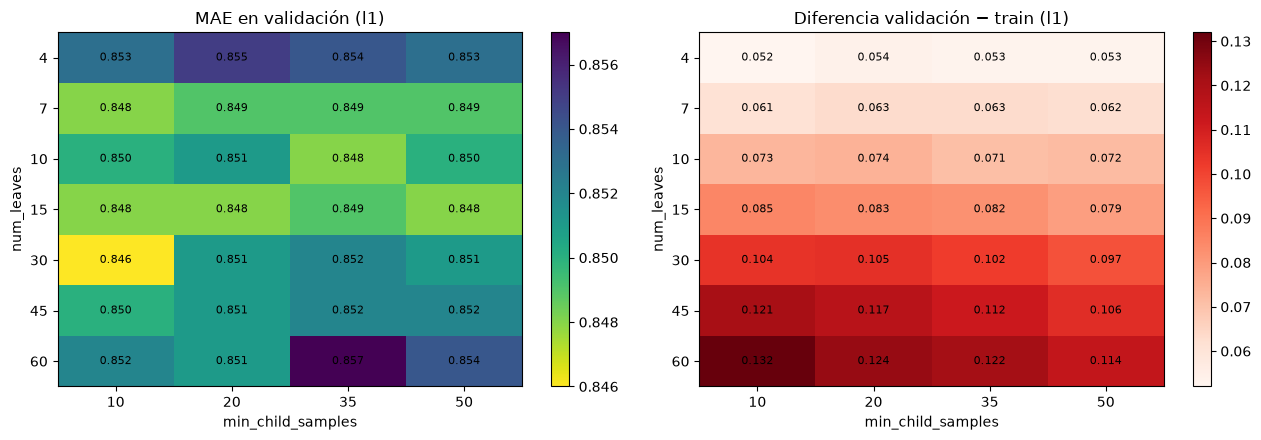

In [169]:
grafico_rejilla_lgbm(ajuste_lgbm_l1, "l1")

A diferencia de las versiones L2, el mapa de MAE en validación de L1 es irregular: no se aprecia una meseta clara y el mejor resultado (30 hojas y `min_child_samples` = 10, MAE 0,846) aparece aislado, rodeado de combinaciones con peor error. La diferencia entre validación y entrenamiento sigue el mismo patrón que en L2, creciendo con el número de hojas, pero es mayor para el mismo tamaño de árbol.

Ninguna combinación de L1 mejora a la versión log (0,834): la mejor queda 0,012 por detrás y prácticamente empata con la versión ratio (0,845). No se ajusta `n_estimators`, ya que en las versiones L2 su efecto sobre el MAE no superó las 5 milésimas, menos de la mitad de la distancia que separa L1 de log. Se descarta L1.

La ventaja de log(ratio) en MAE no se explica solo porque su predicción se acerque a la mediana: apuntar directamente a la mediana con L1 da un resultado peor. Se mantiene L2 con log(ratio) como mejor versión de LightGBM.

## 6. Resultados por fold y predicciones de validación

Resultado del modelo final:

In [170]:
b0 = pd.read_parquet(PREDICTIONS / "b0.parquet")   # predicciones B0

filas = []
for i, mes in enumerate(MESES_VALIDACION):
    _, valid_b0 = obtener_fold(b0, mes)
    m_b0 = metricas(valid_b0["ratio"], valid_b0["pred_B0"])
    filas.append({
        "fold":            mes,
        "MAE_B0":          m_b0["MAE"],
        "MAE_ratio":       resultados_lgbm.loc[i, "MAE"],
        "MAE_log(ratio)":  resultados_lgbm_log.loc[i, "MAE"],
        "RMSE_B0":         m_b0["RMSE"],
        "RMSE_ratio":      resultados_lgbm.loc[i, "RMSE"],
        "RMSE_log(ratio)": resultados_lgbm_log.loc[i, "RMSE"],
    })

comparacion_lgbm = pd.DataFrame(filas).set_index("fold")
comparacion_lgbm.loc["media"] = comparacion_lgbm.mean()

# Mejora respecto a B0 (%), en MAE
comparacion_lgbm["mejora_MAE_ratio_%"] = (1 - comparacion_lgbm["MAE_ratio"] / comparacion_lgbm["MAE_B0"]) * 100
comparacion_lgbm["mejora_MAE_log(ratio)_%"] = (1 - comparacion_lgbm["MAE_log(ratio)"] / comparacion_lgbm["MAE_B0"]) * 100
comparacion_lgbm.round(3)

,MAE_B0,MAE_ratio,MAE_log(ratio),RMSE_B0,RMSE_ratio,RMSE_log(ratio),mejora_MAE_ratio_%,mejora_MAE_log(ratio)_%
fold,,,,,,,,
2026-02,1.140,0.901,0.897,1.779,1.281,1.359,20.903,21.280
2026-03,1.086,0.813,0.800,1.672,1.187,1.256,25.114,26.304
2026-04,1.092,0.822,0.806,1.680,1.181,1.254,24.760,26.168
media,1.106,0.845,0.834,1.711,1.216,1.289,23.551,24.533


In [171]:
modelo_ratio = LGBMRegressor(num_leaves=7, min_child_samples=35, n_estimators=750,
                             learning_rate=0.05, random_state=42, verbose=-1)
modelo_log = LGBMRegressor(num_leaves=10, min_child_samples=35, n_estimators=500,
                           learning_rate=0.05, random_state=42, verbose=-1)

resultados_lgbm, pred_ratio = evaluar_en_folds(modelo_ratio, df, MESES_VALIDACION)
resultados_lgbm_log, pred_log = evaluar_en_folds(modelo_log, df, MESES_VALIDACION, log=True)


p_ratio, p_log = modelo_ratio.get_params(), modelo_log.get_params()
mejor_l1 = ajuste_lgbm_l1.loc[ajuste_lgbm_l1["MAE_medio_val"].idxmin()]

resumen_lgbm = pd.DataFrame({
    "versión":           ["L2 ratio", "L2 log(ratio)", "L1 ratio (descartada)"],
    "num_leaves":        [p_ratio["num_leaves"], p_log["num_leaves"], mejor_l1["num_leaves"]],
    "min_child_samples": [p_ratio["min_child_samples"], p_log["min_child_samples"], mejor_l1["min_child_samples"]],
    "n_estimators":      [p_ratio["n_estimators"], p_log["n_estimators"], 500],
    "MAE_medio_val":     [resultados_lgbm["MAE"].mean(), resultados_lgbm_log["MAE"].mean(),
                          mejor_l1["MAE_medio_val"]],
    "RMSE_medio_val":    [resultados_lgbm["RMSE"].mean(), resultados_lgbm_log["RMSE"].mean(),
                          mejor_l1["RMSE_medio"]],
})
resumen_lgbm.round(3)

,versión,num_leaves,min_child_samples,n_estimators,MAE_medio_val,RMSE_medio_val
0,L2 ratio,7,35,750,0.845,1.216
1,L2 log(ratio),10,35,500,0.834,1.289
2,L1 ratio (descartada),30,10,500,0.846,1.317


Cada versión se evalúa con su propia configuración, elegida con el mismo procedimiento y criterio, por lo que la comparación entre ellas es justa aunque sus hiperparámetros sean distintos.

La versión log(ratio) obtiene el menor MAE (0,834 frente a 0,845 en ratio) y la versión ratio, el menor RMSE (1,216 frente a 1,289). Es el mismo comportamiento observado en Ridge y en Random Forest: la versión log reduce el error en la fase típica, pero comete más error en las fases con desviaciones grandes. L1 no mejora a ninguna de las dos: empata con ratio en MAE y obtiene el peor RMSE.

Como el MAE es la métrica principal, se considera log(ratio) la mejor versión de LightGBM.

Las predicciones de validación de ambas versiones se guardan para la evaluación final (notebook 15):

In [172]:
pred_lgbm_valid = pred_ratio.rename(columns={"pred": "pred_lgbm_ratio"})
pred_lgbm_valid["pred_lgbm_log"] = pred_log["pred"].values

pred_lgbm_valid.to_parquet(PREDICTIONS / "lgbm_valid.parquet", index=False)
print(pred_lgbm_valid.shape)

(2871, 5)


## 7. Predicciones de test

Con los hiperparámetros congelados en validación, se reentrena con todo el conjunto de desarrollo y se predice el
test. Aquí solo se guardan las predicciones: el test se evalúa una única vez, en el notebook 15.

In [173]:
desarrollo = df[df["split"] == "desarrollo"]
test = df[df["split"] == "test"]

pred_lgbm_test = pd.DataFrame({
    "IDMOTask":        test["IDMOTask"].values,
    "mes_orden":       test["mes_orden"].values,
    "ratio":           test[OBJETIVO].values,
    "pred_lgbm_ratio": ajustar_y_predecir(modelo_final, desarrollo, test),
    "pred_lgbm_log":   ajustar_y_predecir(modelo_final, desarrollo, test, log=True),
})

print(pred_lgbm_test.shape, pred_lgbm_test.isna().sum().sum())
pred_lgbm_test.to_parquet(PREDICTIONS / "lgbm_test.parquet", index=False)

(2385, 5) 0
